# Week 02 — YCB-V Dataset Explorer

**Group 1 | Side Quest: Dataset Understanding II**

Goal: load YCB-Video programmatically, build a small explorer for RGB/depth/masks/boxes, calculate basic statistics, and check simple data issues.

This notebook reuses the **YCB-V BOP'19 test subset** from Week 1. No model training yet.

## 1. Imports
Only the libraries needed for loading, visualization, tables, and downloading the dataset if it is missing.

In [1]:
%pip -q install huggingface_hub pillow matplotlib pandas

from pathlib import Path
import json
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from huggingface_hub import hf_hub_download

print("Ready")

Ready


## 2. Dataset path
If Week 1 already downloaded the dataset, this cell reuses it. Otherwise it downloads the same BOP subset.

In [2]:
DATASETS_DIR = Path("datasets")
DOWNLOAD_DIR = DATASETS_DIR / "downloads"
DATASET_ROOT = DATASETS_DIR / "ycbv"
TEST_DIR = DATASET_ROOT / "test"

DATASETS_DIR.mkdir(exist_ok=True)
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

if not TEST_DIR.exists():
    REPO_ID = "bop-benchmark/ycbv"

    base_zip = Path(hf_hub_download(
        repo_id=REPO_ID,
        filename="ycbv_base.zip",
        repo_type="dataset",
        local_dir=DOWNLOAD_DIR
    ))

    test_zip = Path(hf_hub_download(
        repo_id=REPO_ID,
        filename="ycbv_test_bop19.zip",
        repo_type="dataset",
        local_dir=DOWNLOAD_DIR
    ))

    if not DATASET_ROOT.exists():
        with zipfile.ZipFile(base_zip, "r") as z:
            z.extractall(DATASETS_DIR)

    DATASET_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(test_zip, "r") as z:
        z.extractall(DATASET_ROOT)

print("Dataset root:", DATASET_ROOT.resolve())
print("Test folder exists:", TEST_DIR.exists())

ycbv_base.zip: reconstructing file:   0%|          |  0.00B / 15.8kB            

ycbv_base.zip: downloading bytes:           |  0.00B            

ycbv_test_bop19.zip: reconstructing file:   0%|          |  0.00B /  660MB            

ycbv_test_bop19.zip: downloading bytes:           |  0.00B            

Dataset root: /content/datasets/ycbv
Test folder exists: True


## 3. Loader
These functions connect one frame to its RGB, depth, camera, object annotations, masks, and bounding boxes.

In [3]:
YCB_NAMES = {
    1: "002_master_chef_can",
    2: "003_cracker_box",
    3: "004_sugar_box",
    4: "005_tomato_soup_can",
    5: "006_mustard_bottle",
    6: "007_tuna_fish_can",
    7: "008_pudding_box",
    8: "009_gelatin_box",
    9: "010_potted_meat_can",
    10: "011_banana",
    11: "019_pitcher_base",
    12: "021_bleach_cleanser",
    13: "024_bowl",
    14: "025_mug",
    15: "035_power_drill",
    16: "036_wood_block",
    17: "037_scissors",
    18: "040_large_marker",
    19: "051_large_clamp",
    20: "052_extra_large_clamp",
    21: "061_foam_brick",
}

def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def get_scene_dir(scene_id):
    return TEST_DIR / f"{scene_id:06d}"

def load_frame(scene_id, image_id):
    scene_dir = get_scene_dir(scene_id)
    name = f"{image_id:06d}.png"

    scene_camera = load_json(scene_dir / "scene_camera.json")
    scene_gt = load_json(scene_dir / "scene_gt.json")
    scene_gt_info = load_json(scene_dir / "scene_gt_info.json")

    rgb = np.array(Image.open(scene_dir / "rgb" / name).convert("RGB"))
    depth_raw = np.array(Image.open(scene_dir / "depth" / name))

    camera = scene_camera[str(image_id)]
    objects = scene_gt[str(image_id)]
    infos = scene_gt_info[str(image_id)]

    masks = []
    visible_masks = []

    for i in range(len(objects)):
        mask_path = scene_dir / "mask" / f"{image_id:06d}_{i:06d}.png"
        vis_path = scene_dir / "mask_visib" / f"{image_id:06d}_{i:06d}.png"

        masks.append(np.array(Image.open(mask_path)) if mask_path.exists() else None)
        visible_masks.append(np.array(Image.open(vis_path)) if vis_path.exists() else None)

    return {
        "scene_id": scene_id,
        "image_id": image_id,
        "rgb": rgb,
        "depth_raw": depth_raw,
        "depth_mm": depth_raw.astype(np.float32) * camera["depth_scale"],
        "camera": camera,
        "objects": objects,
        "infos": infos,
        "masks": masks,
        "visible_masks": visible_masks,
    }

scene_dirs = sorted([p for p in TEST_DIR.iterdir() if p.is_dir()])
print("Scenes:", len(scene_dirs))

Scenes: 12


## 4. Dataset tables
`frame_df` is one row per image. `instance_df` is one row per object instance. These tables make statistics easier.

In [4]:
frame_rows = []
instance_rows = []

for scene_dir in scene_dirs:
    scene_id = int(scene_dir.name)
    scene_gt = load_json(scene_dir / "scene_gt.json")
    scene_gt_info = load_json(scene_dir / "scene_gt_info.json")

    rgb_files = sorted((scene_dir / "rgb").glob("*.png"))

    for rgb_path in rgb_files:
        image_id = int(rgb_path.stem)
        objects = scene_gt[str(image_id)]
        infos = scene_gt_info[str(image_id)]

        frame_rows.append({
            "scene_id": scene_id,
            "image_id": image_id,
            "object_count": len(objects),
            "rgb_path": str(rgb_path),
        })

        for i, (obj, info) in enumerate(zip(objects, infos)):
            x, y, w, h = info["bbox_visib"]
            instance_rows.append({
                "scene_id": scene_id,
                "image_id": image_id,
                "instance_id": i,
                "obj_id": obj["obj_id"],
                "class_name": YCB_NAMES.get(obj["obj_id"], f"obj_{obj['obj_id']}"),
                "visibility": info.get("visib_fract", np.nan),
                "bbox_width": w,
                "bbox_height": h,
                "bbox_area": w * h,
            })

frame_df = pd.DataFrame(frame_rows)
instance_df = pd.DataFrame(instance_rows)

display(frame_df.head())
display(instance_df.head())

print("Frames:", len(frame_df))
print("Object instances:", len(instance_df))

,scene_id,image_id,object_count,rgb_path
0,48,1,5,datasets/ycbv/test/000048/rgb/000001.png
1,48,36,5,datasets/ycbv/test/000048/rgb/000036.png
2,48,47,5,datasets/ycbv/test/000048/rgb/000047.png
3,48,83,5,datasets/ycbv/test/000048/rgb/000083.png
4,48,112,5,datasets/ycbv/test/000048/rgb/000112.png


,scene_id,image_id,instance_id,obj_id,class_name,visibility,bbox_width,bbox_height,bbox_area
0,48,1,0,1,002_master_chef_can,0.935144,132,192,25344
1,48,1,1,6,007_tuna_fish_can,0.997410,112,73,8176
2,48,1,2,14,025_mug,0.996978,137,113,15481
3,48,1,3,19,051_large_clamp,0.981809,90,213,19170
4,48,1,4,20,052_extra_large_clamp,0.999282,349,127,44323


Frames: 900
Object instances: 4125


## 5. Dataset explorer
Choose any row from `frame_df`. This shows RGB, depth, visible masks, and bounding boxes for the same frame.

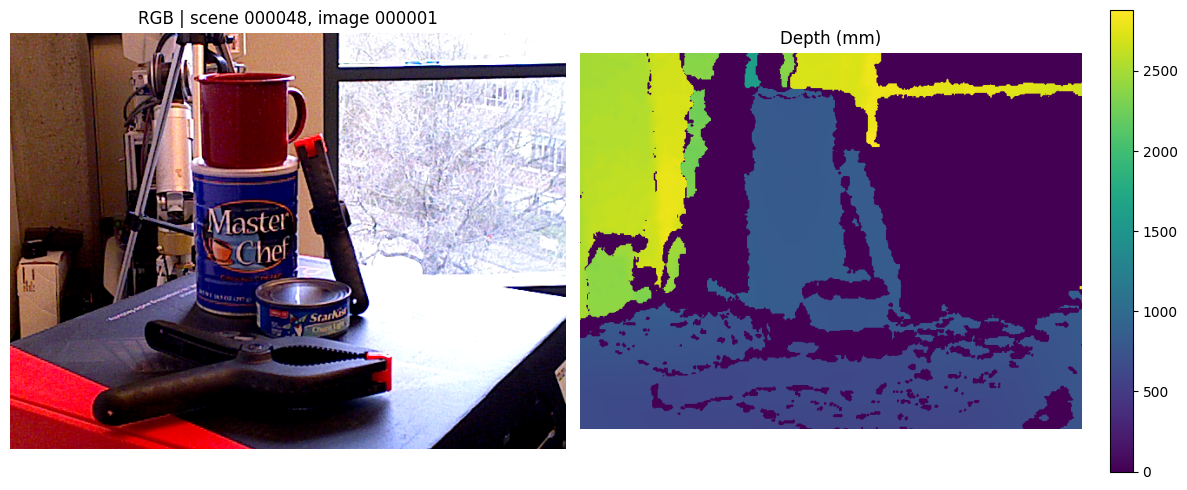

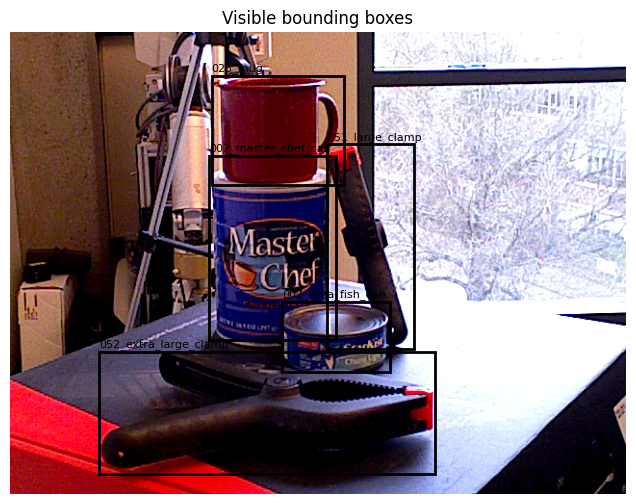

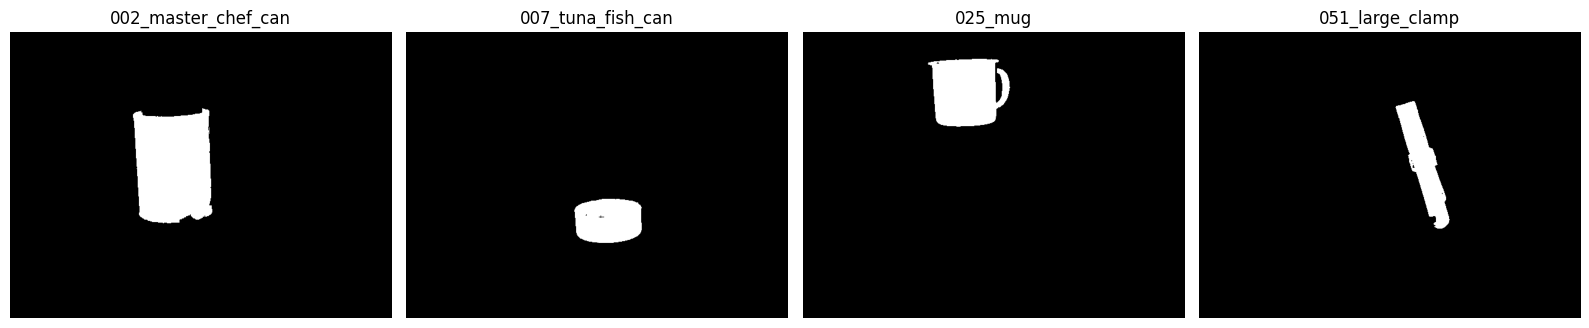

RGB shape: (480, 640, 3)
Depth shape: (480, 640)
Objects in frame: 5
Object IDs: [1, 6, 14, 19, 20]


In [5]:
SAMPLE_INDEX = 0

sample_row = frame_df.iloc[SAMPLE_INDEX]
sample = load_frame(
    int(sample_row["scene_id"]),
    int(sample_row["image_id"])
)

rgb = sample["rgb"]
depth_mm = sample["depth_mm"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(rgb)
axes[0].set_title(
    f"RGB | scene {sample['scene_id']:06d}, image {sample['image_id']:06d}"
)
axes[0].axis("off")

depth_view = axes[1].imshow(depth_mm)
axes[1].set_title("Depth (mm)")
axes[1].axis("off")
fig.colorbar(depth_view, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(rgb)

for obj, info in zip(sample["objects"], sample["infos"]):
    x, y, w, h = info["bbox_visib"]
    obj_id = obj["obj_id"]

    ax.add_patch(Rectangle(
        (x, y), w, h,
        fill=False,
        linewidth=2
    ))
    ax.text(
        x,
        max(0, y - 5),
        YCB_NAMES.get(obj_id, str(obj_id)),
        fontsize=8
    )

ax.set_title("Visible bounding boxes")
ax.axis("off")
plt.show()

n_masks = min(4, len(sample["visible_masks"]))

if n_masks:
    fig, axes = plt.subplots(1, n_masks, figsize=(4 * n_masks, 4))
    axes = np.atleast_1d(axes)

    for i in range(n_masks):
        mask = sample["visible_masks"][i]
        obj_id = sample["objects"][i]["obj_id"]

        axes[i].imshow(mask, cmap="gray")
        axes[i].set_title(YCB_NAMES.get(obj_id, str(obj_id)))
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

print("RGB shape:", rgb.shape)
print("Depth shape:", sample["depth_raw"].shape)
print("Objects in frame:", len(sample["objects"]))
print("Object IDs:", [obj["obj_id"] for obj in sample["objects"]])

## 6. Basic statistics
Count frames, scenes, object frequencies, objects per frame, visibility, and bounding-box sizes.

Number of scenes: 12
Number of frames: 900
Number of object instances: 4125
Unique object classes: 21

Objects per frame:


,object_count
count,900.000000
mean,4.583333
std,0.954324
min,3.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,6.000000



Visibility:


,visibility
count,4125.000000
mean,0.896583
std,0.155529
min,0.075392
25%,0.804264
50%,0.990229
75%,0.999065
max,1.000000



Bounding-box area:


,bbox_area
count,4125.000000
mean,26829.728242
std,17606.905702
min,2726.000000
25%,13908.000000
50%,22195.000000
75%,34760.000000
max,106190.000000


,obj_id,class_name,instances
3,4,005_tomato_soup_can,450
2,3,004_sugar_box,375
0,1,002_master_chef_can,300
11,12,021_bleach_cleanser,300
5,6,007_tuna_fish_can,300
14,15,035_power_drill,300
1,2,003_cracker_box,225
8,9,010_potted_meat_can,225
10,11,019_pitcher_base,225
4,5,006_mustard_bottle,150


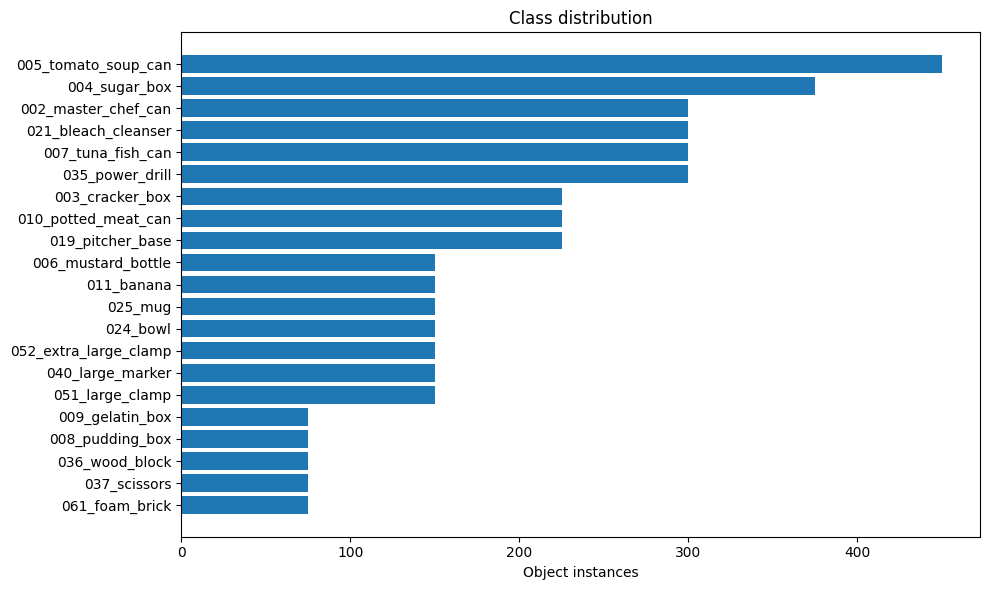

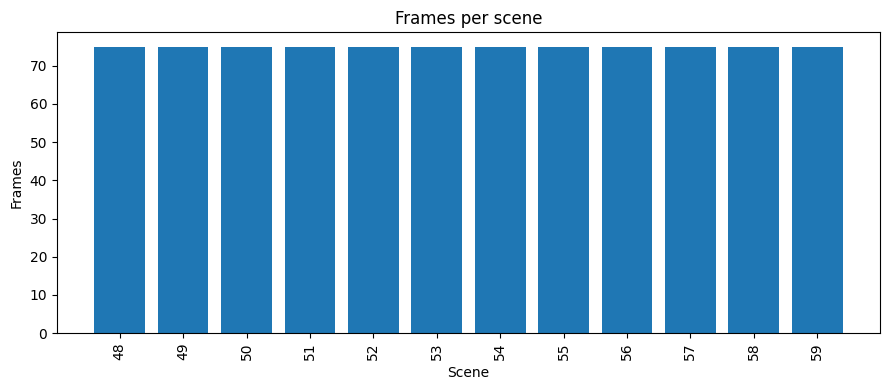

In [6]:
print("Number of scenes:", frame_df["scene_id"].nunique())
print("Number of frames:", len(frame_df))
print("Number of object instances:", len(instance_df))
print("Unique object classes:", instance_df["obj_id"].nunique())

print("\nObjects per frame:")
display(frame_df["object_count"].describe())

print("\nVisibility:")
display(instance_df["visibility"].describe())

print("\nBounding-box area:")
display(instance_df["bbox_area"].describe())

class_counts = (
    instance_df.groupby(["obj_id", "class_name"])
    .size()
    .reset_index(name="instances")
    .sort_values("instances", ascending=False)
)

display(class_counts)

plt.figure(figsize=(10, 6))
plt.barh(class_counts["class_name"], class_counts["instances"])
plt.gca().invert_yaxis()
plt.xlabel("Object instances")
plt.title("Class distribution")
plt.tight_layout()
plt.show()

frames_per_scene = frame_df.groupby("scene_id").size()

plt.figure(figsize=(9, 4))
plt.bar(frames_per_scene.index.astype(str), frames_per_scene.values)
plt.xlabel("Scene")
plt.ylabel("Frames")
plt.title("Frames per scene")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 7. Data-quality checks
Check missing RGB/depth files, missing masks, invalid boxes, and highly occluded object instances.

In [7]:
issues = []

missing_depth = 0
missing_mask = 0
missing_visible_mask = 0

for row in frame_df.itertuples(index=False):
    scene_dir = get_scene_dir(int(row.scene_id))
    image_id = int(row.image_id)
    name = f"{image_id:06d}.png"

    if not (scene_dir / "depth" / name).exists():
        missing_depth += 1

for row in instance_df.itertuples(index=False):
    scene_dir = get_scene_dir(int(row.scene_id))
    image_id = int(row.image_id)
    instance_id = int(row.instance_id)

    mask_path = scene_dir / "mask" / f"{image_id:06d}_{instance_id:06d}.png"
    vis_path = scene_dir / "mask_visib" / f"{image_id:06d}_{instance_id:06d}.png"

    if not mask_path.exists():
        missing_mask += 1

    if not vis_path.exists():
        missing_visible_mask += 1

invalid_boxes = int(
    ((instance_df["bbox_width"] <= 0) | (instance_df["bbox_height"] <= 0)).sum()
)

highly_occluded = int((instance_df["visibility"] < 0.25).sum())

issues.append(("Missing depth files", missing_depth))
issues.append(("Missing full masks", missing_mask))
issues.append(("Missing visible masks", missing_visible_mask))
issues.append(("Invalid visible boxes", invalid_boxes))
issues.append(("Instances with visibility < 25%", highly_occluded))

issues_df = pd.DataFrame(issues, columns=["check", "count"])
display(issues_df)

print("Low-visibility examples:")
display(
    instance_df.sort_values("visibility")
    [["scene_id", "image_id", "class_name", "visibility", "bbox_area"]]
    .head(10)
)

,check,count
0,Missing depth files,0
1,Missing full masks,0
2,Missing visible masks,0
3,Invalid visible boxes,0
4,Instances with visibility < 25%,23


Low-visibility examples:


,scene_id,image_id,class_name,visibility,bbox_area
716,50,653,005_tomato_soup_can,0.075392,9204
696,50,640,005_tomato_soup_can,0.094505,9594
726,50,662,005_tomato_soup_can,0.104733,10112
711,50,651,005_tomato_soup_can,0.104964,9480
731,50,671,005_tomato_soup_can,0.110280,9360
681,50,623,005_tomato_soup_can,0.114325,9424
721,50,660,005_tomato_soup_can,0.118010,10112
691,50,633,005_tomato_soup_can,0.119289,9086
701,50,642,005_tomato_soup_can,0.119446,9438
736,50,681,005_tomato_soup_can,0.127263,9875


## 8. Save Week 2 outputs
Save reusable tables and a small JSON summary for the weekly report.

In [8]:
OUTPUT_DIR = Path("week02_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

frame_df.to_csv(OUTPUT_DIR / "frame_index.csv", index=False)
instance_df.to_csv(OUTPUT_DIR / "instance_index.csv", index=False)
class_counts.to_csv(OUTPUT_DIR / "class_counts.csv", index=False)
issues_df.to_csv(OUTPUT_DIR / "data_quality_checks.csv", index=False)

summary = {
    "scenes": int(frame_df["scene_id"].nunique()),
    "frames": int(len(frame_df)),
    "object_instances": int(len(instance_df)),
    "unique_classes": int(instance_df["obj_id"].nunique()),
    "mean_objects_per_frame": float(frame_df["object_count"].mean()),
    "mean_visibility": float(instance_df["visibility"].mean()),
    "missing_depth_files": int(missing_depth),
    "missing_full_masks": int(missing_mask),
    "missing_visible_masks": int(missing_visible_mask),
    "invalid_visible_boxes": int(invalid_boxes),
    "highly_occluded_instances": int(highly_occluded),
}

with open(OUTPUT_DIR / "week02_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))
print("\nSaved to:", OUTPUT_DIR.resolve())

{
  "scenes": 12,
  "frames": 900,
  "object_instances": 4125,
  "unique_classes": 21,
  "mean_objects_per_frame": 4.583333333333333,
  "mean_visibility": 0.896582697997909,
  "missing_depth_files": 0,
  "missing_full_masks": 0,
  "missing_visible_masks": 0,
  "invalid_visible_boxes": 0,
  "highly_occluded_instances": 23
}

Saved to: /content/week02_outputs


## 9. Week 2 observations

Fill these after running the notebook.

- **Class distribution:** ...
- **Objects per frame:** ...
- **Occlusion / visibility:** ...
- **Bounding-box sizes:** ...
- **Data issues:** ...
- **Most useful explorer view:** ...

### Main Quest notes
Write only the Neural Networks and Deep Learning concepts you actually studied this week.

### Conclusion
> ...

### Submission checklist
- [ ] YCB-V loaded programmatically
- [ ] RGB/depth/masks/boxes explorer works
- [ ] Frame and instance tables created
- [ ] Class distribution calculated
- [ ] Basic dataset statistics calculated
- [ ] Data-quality checks completed
- [ ] Outputs saved
- [ ] Main Quest progress written
- [ ] Weekly DOCX report completed
- [ ] No model training yet